# Imports

In [1]:
from __future__ import annotations

from datetime import datetime, timedelta
import os
from pathlib import Path

os.environ.setdefault("XDG_CACHE_HOME", "/tmp")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import pyarrow.parquet as pq
import pycountry
import seaborn as sns
import plotly.express as px

# Parameters

In [2]:
# Notebook parameters
# START_DATE_BEFORE_AI = datetime(2021, 1, 1)
# END_DATE_BEFORE_AI = datetime(2022, 12, 31)
# START_DATE_AFTER_AI = datetime(2023, 1, 1)
# END_DATE_AFTER_AI = datetime(2026, 6, 9)

# Test split that uses the existing parsed 2023 data for both periods.
# These are artificial before/after labels for development and plots only.
START_DATE_BEFORE_AI = datetime(2023, 1, 1)
END_DATE_BEFORE_AI = datetime(2023, 1, 15)
START_DATE_AFTER_AI = datetime(2023, 1, 16)
END_DATE_AFTER_AI = datetime(2023, 2, 1)

MIN_ARTICLES_PER_COMMUNITY = 50
TOP_COMMUNITIES_TO_PLOT = 20

In [ ]:
TONE_COLUMNS = [
    "tone",
    "positive_score",
    "negative_score",
    "polarity",
]
ANXIETY_COLUMNS = [
    "liwc_anxiety",
    "wordnet_anxiety",
    "wordnet_fear",
    "lm_uncertainty",
]
OPPORTUNITY_COLUMNS = [
    "wordnet_hope",
    "wordnet_optimism",
]
FEELING_COLUMNS = [
    "liwc_anger",
    "liwc_anxiety",
    "lm_uncertainty",
    "wordnet_anger",
    "wordnet_anxiety",
    "wordnet_fear",
    "wordnet_hope",
    "wordnet_optimism",
    "wordnet_feeling",
]
LOAD_COLUMNS = [
    "period",
    "date",
    "gkg_record_id",
    "article_domain",
    "primary_location",
    "primary_location_country_code",
    "primary_location_latitude",
    "primary_location_longitude",
    "sentiment",
    "dominant_feeling",
    *TONE_COLUMNS,
    *FEELING_COLUMNS,
]

# Setup

In [4]:
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update(
    {
        "axes.titlesize": 18,
        "axes.labelsize": 15,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "figure.titlesize": 20,
    }
)
pd.options.display.float_format = "{:,.3f}".format

In [5]:
def find_project_dir() -> Path:
    """Find the Project folder from a notebook or script working directory.

    Returns:
        Path to the project directory that contains data, result, and src.
    """

    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd() / "Project",
        Path.cwd().parent / "Project",
    ]
    for candidate in candidates:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Could not find the Project directory.")

In [6]:
project_dir = find_project_dir()
parsed_gdelt_data_folder = project_dir / "data" / "parsed"
result_dir = project_dir / "result"
result_dir.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {project_dir}")
print(f"Parsed data folder: {parsed_gdelt_data_folder}")
print(f"Result directory: {result_dir}")

Project directory: /home/amitner/Data-Mining-Assignments/Project
Parsed data folder: /home/amitner/Data-Mining-Assignments/Project/data/parsed
Result directory: /home/amitner/Data-Mining-Assignments/Project/result


# Load Data

## Loading

In [7]:
def load_parsed_gdelt_data(
    data_folder: Path,
    columns: list[str],
) -> pd.DataFrame:
    """Load all completed parsed GDELT parquet files.

    Args:
        data_folder: Folder containing parsed GDELT parquet files.
        columns: Columns to read from each parquet file.

    Returns:
        Combined article-level parsed GDELT data.
    """

    paths = sorted(data_folder.glob("parsed_gkg_*.parquet"))
    if not paths:
        raise FileNotFoundError(f"No parsed parquet files found in {data_folder}")

    frames = []
    for path in paths:
        parquet_file = pq.ParquetFile(path)
        available_columns = set(parquet_file.schema_arrow.names)
        selected_columns = [column for column in columns if column in available_columns]
        print(f"Loading {path.name}: {parquet_file.metadata.num_rows:,} rows")
        frames.append(pq.read_table(path, columns=selected_columns).to_pandas())

    data = pd.concat(frames, ignore_index=True)
    data["date"] = pd.to_datetime(data["date"], errors="coerce")
    numeric_columns = [
        "primary_location_latitude",
        "primary_location_longitude",
        *TONE_COLUMNS,
        *FEELING_COLUMNS,
    ]
    for column in numeric_columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    return data

In [8]:
def filter_study_periods(data: pd.DataFrame) -> pd.DataFrame:
    """Keep records inside the configured before-AI and after-AI windows.

    Args:
        data: Parsed article-level GDELT records.

    Returns:
        Filtered records with a clean period label.
    """

    before_end = END_DATE_BEFORE_AI + timedelta(days=1)
    after_end = END_DATE_AFTER_AI + timedelta(days=1)
    before_mask = data["date"].between(
        START_DATE_BEFORE_AI,
        before_end,
        inclusive="left",
    )
    after_mask = data["date"].between(
        START_DATE_AFTER_AI,
        after_end,
        inclusive="left",
    )
    filtered = data.loc[before_mask | after_mask].copy()
    filtered["period"] = "after_ai"
    filtered.loc[
        filtered["date"].between(
            START_DATE_BEFORE_AI,
            before_end,
            inclusive="left",
        ),
        "period",
    ] = "before_ai"
    filtered["period"] = filtered["period"].astype("string")
    return filtered

In [9]:
def country_name(country_code: object) -> str:
    """Convert a GDELT country code into a readable country name.

    Args:
        country_code: GDELT country code, usually ISO alpha-2.

    Returns:
        Country name when available; otherwise the original code or Unknown.
    """

    code = str(country_code).strip().upper()
    if not code or code == "<NA>":
        return "Unknown"
    country = pycountry.countries.get(alpha_2=code)
    return country.name if country else code

In [10]:
def country_alpha3(country_code: object) -> str | None:
    """Convert a GDELT country code into ISO alpha-3 for global maps.

    Args:
        country_code: GDELT country code, usually ISO alpha-2.

    Returns:
        ISO alpha-3 country code, or None when no match is found.
    """

    code = str(country_code).strip().upper()
    country = pycountry.countries.get(alpha_2=code)
    return country.alpha_3 if country else None

In [11]:
def add_analysis_columns(data: pd.DataFrame) -> pd.DataFrame:
    """Add country, anxiety, and opportunity measures.

    Args:
        data: Parsed article-level GDELT records.

    Returns:
        Data with additional analysis columns.
    """

    enriched = data.copy()
    enriched["community"] = enriched["primary_location_country_code"].map(
        country_name
    )
    enriched["country_iso3"] = enriched["primary_location_country_code"].map(
        country_alpha3
    )
    enriched["anxiety_score"] = enriched[ANXIETY_COLUMNS].mean(axis=1)
    enriched["opportunity_score"] = enriched[OPPORTUNITY_COLUMNS].mean(axis=1)
    enriched["ai_anxiety_index"] = (
        enriched["anxiety_score"] - enriched["opportunity_score"]
    )
    enriched["month"] = enriched["date"].dt.to_period("M").dt.to_timestamp()
    enriched.loc[enriched["community"] == "Unknown", "community"] = pd.NA
    return enriched.dropna(subset=["date", "community"])

In [12]:
articles = load_parsed_gdelt_data(parsed_gdelt_data_folder, LOAD_COLUMNS)
articles = filter_study_periods(articles)
articles = add_analysis_columns(articles)

print(f"Loaded articles in study windows: {len(articles):,}")
articles.head()

Loading parsed_gkg_after_ai_20230101_20230131.parquet: 1,932,333 rows
Loading parsed_gkg_after_ai_20230201_20230201.parquet: 87,108 rows
Loaded articles in study windows: 1,661,315


,period,date,gkg_record_id,article_domain,primary_location,primary_location_country_code,primary_location_latitude,primary_location_longitude,sentiment,dominant_feeling,...,wordnet_fear,wordnet_hope,wordnet_optimism,wordnet_feeling,community,country_iso3,anxiety_score,opportunity_score,ai_anxiety_index,month
0,before_ai,2023-01-01,20230101000000-1,www.voazimbabwe.com,Italian,IT,NaN,42.833,negative,wordnet_feeling,...,NaN,2.000,NaN,14.000,Italy,ITA,6.000,2.000,4.000,2023-01-01
1,before_ai,2023-01-01,20230101000000-4,www.annistonstar.com,"Alabama, United States",US,NaN,32.799,neutral,wordnet_feeling,...,NaN,NaN,NaN,7.000,United States,USA,5.000,NaN,NaN,2023-01-01
3,before_ai,2023-01-01,20230101000000-14,www.mdjonline.com,Colombian,CO,NaN,4.000,neutral,wordnet_feeling,...,NaN,NaN,NaN,14.000,Colombia,COL,4.000,NaN,NaN,2023-01-01
5,before_ai,2023-01-01,20230101000000-19,www.hampshirechronicle.co.uk,Russia,RS,NaN,60.000,positive,wordnet_feeling,...,2.000,3.000,2.000,12.000,Serbia,SRB,2.333,2.500,-0.167,2023-01-01
6,before_ai,2023-01-01,20230101000000-20,pakobserver.net,"Munich, Bayern, Germany",GM,"16,532.000",48.150,negative,wordnet_feeling,...,NaN,NaN,NaN,9.000,Gambia,GMB,1.000,NaN,NaN,2023-01-01


## Statistics and Visualization

In [13]:
def save_table(data: pd.DataFrame, filename: str) -> Path:
    """Save a DataFrame to the result folder.

    Args:
        data: Table to save.
        filename: CSV filename under the result folder.

    Returns:
        Path to the saved table.
    """

    path = result_dir / filename
    data.to_csv(path, index=False)
    print(f"Saved table: {path}")
    return path

In [14]:
def save_graph_tables(graph: nx.Graph, prefix: str) -> tuple[Path, Path]:
    """Save NetworkX graph nodes and edges as CSV files.

    Args:
        graph: NetworkX graph to export.
        prefix: Filename prefix for node and edge tables.

    Returns:
        Paths to the node and edge CSV files.
    """

    node_table = pd.DataFrame(
        {"node": node, **attributes}
        for node, attributes in graph.nodes(data=True)
    )
    edge_table = pd.DataFrame(
        {"source": source, "target": target, **attributes}
        for source, target, attributes in graph.edges(data=True)
    )
    node_path = save_table(node_table, f"{prefix}_nodes.csv")
    edge_path = save_table(edge_table, f"{prefix}_edges.csv")
    return node_path, edge_path

In [15]:
def save_current_figure(filename: str) -> Path:
    """Save and display the current matplotlib figure.

    Args:
        filename: Image filename under the result folder.

    Returns:
        Path to the saved figure.
    """

    path = result_dir / filename
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved figure: {path}")
    plt.show()
    return path

In [16]:
def running_in_notebook() -> bool:
    """Check whether the analysis is running inside a notebook kernel.

    Returns:
        True when the current process is an interactive notebook.
    """

    try:
        from IPython import get_ipython
    except ImportError:
        return False

    shell = get_ipython()
    if shell is None:
        return False
    return shell.__class__.__name__ == "ZMQInteractiveShell"

In [17]:
period_summary = (
    articles.groupby("period", as_index=False)
    .agg(
        articles=("gkg_record_id", "count"),
        communities=("community", "nunique"),
        mean_tone=("tone", "mean"),
        mean_anxiety=("anxiety_score", "mean"),
        mean_opportunity=("opportunity_score", "mean"),
        mean_ai_anxiety_index=("ai_anxiety_index", "mean"),
    )
    .sort_values("period")
)
save_table(period_summary, "ai_anxiety_period_summary.csv")
period_summary

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_period_summary.csv


,period,articles,communities,mean_tone,mean_anxiety,mean_opportunity,mean_ai_anxiety_index
0,after_ai,941464,238,-0.803,3.727,2.042,2.467
1,before_ai,719851,237,-0.732,3.660,2.035,2.338


Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_articles_by_period.png


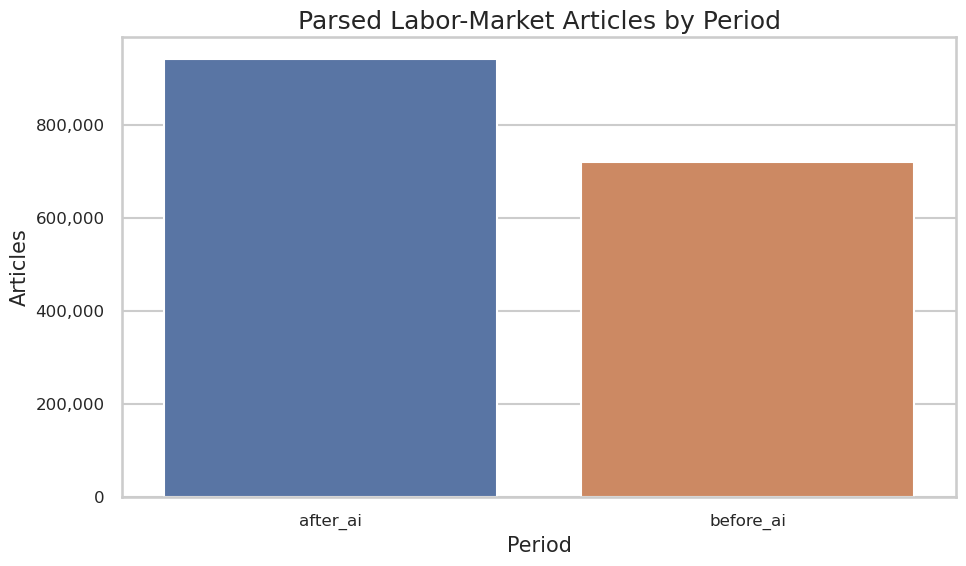

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_articles_by_period.png')

In [18]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=period_summary,
    x="period",
    y="articles",
    hue="period",
    legend=False,
)
plt.title("Parsed Labor-Market Articles by Period")
plt.xlabel("Period")
plt.ylabel("Articles")
plt.gca().yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
save_current_figure("ai_anxiety_articles_by_period.png")

# Geographic Sentiment Analysis

Build global sentiment distribution by region.

## Regional Sentiment Table
Region-Sentiment-Date DataFrame Construction

### Calculation

In [19]:
def build_regional_sentiment_table(data: pd.DataFrame) -> pd.DataFrame:
    """Summarize sentiment and emotion measures by community and period.

    Args:
        data: Article-level analysis records.

    Returns:
        Community-period summary table.
    """

    grouped = (
        data.groupby(["period", "community"], as_index=False)
        .agg(
            country_iso3=("country_iso3", "first"),
            articles=("gkg_record_id", "count"),
            mean_tone=("tone", "mean"),
            positive_score=("positive_score", "mean"),
            negative_score=("negative_score", "mean"),
            anxiety_score=("anxiety_score", "mean"),
            opportunity_score=("opportunity_score", "mean"),
            ai_anxiety_index=("ai_anxiety_index", "mean"),
            latitude=("primary_location_latitude", "mean"),
            longitude=("primary_location_longitude", "mean"),
        )
        .query("articles >= @MIN_ARTICLES_PER_COMMUNITY")
        .sort_values(["period", "ai_anxiety_index"], ascending=[True, False])
    )
    return grouped

In [20]:
regional_sentiment = build_regional_sentiment_table(articles)
save_table(regional_sentiment, "regional_sentiment_summary.csv")
regional_sentiment.head(20)

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/regional_sentiment_summary.csv


,period,community,country_iso3,articles,mean_tone,positive_score,negative_score,anxiety_score,opportunity_score,ai_anxiety_index,latitude,longitude
193,after_ai,Serbia,SRB,91075,-2.174,2.601,4.775,5.936,2.426,6.164,"25,123.211",59.239
80,after_ai,Gibraltar,GIB,493,-3.516,1.567,5.083,4.047,1.031,4.507,"16,673.000",36.133
219,after_ai,UV,NaN,144,-1.699,2.875,4.575,3.435,1.509,4.165,"154,461.564",12.806
91,after_ai,IC,NaN,209,-0.421,2.544,2.965,5.335,1.763,4.012,"17,530.575",64.747
175,after_ai,Romania,ROU,5947,-1.309,2.693,4.002,4.207,1.713,3.660,"24,873.881",45.907
107,after_ai,KV,NaN,254,-1.813,2.800,4.613,3.310,1.760,3.424,"46,313.606",42.598
25,after_ai,Bhutan,BTN,54,1.745,3.958,2.213,3.706,1.792,3.393,"6,081.526",27.472
174,after_ai,RQ,NaN,792,-0.087,3.121,3.208,4.558,1.814,3.356,NaN,18.236
56,after_ai,EI,NaN,8469,-0.398,2.934,3.332,4.110,1.937,3.178,"18,386.360",53.144
155,after_ai,Norway,NOR,2969,-0.788,2.342,3.130,5.893,1.983,3.112,"23,342.026",62.391


### Visualization

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/top_ai_anxiety_communities.png


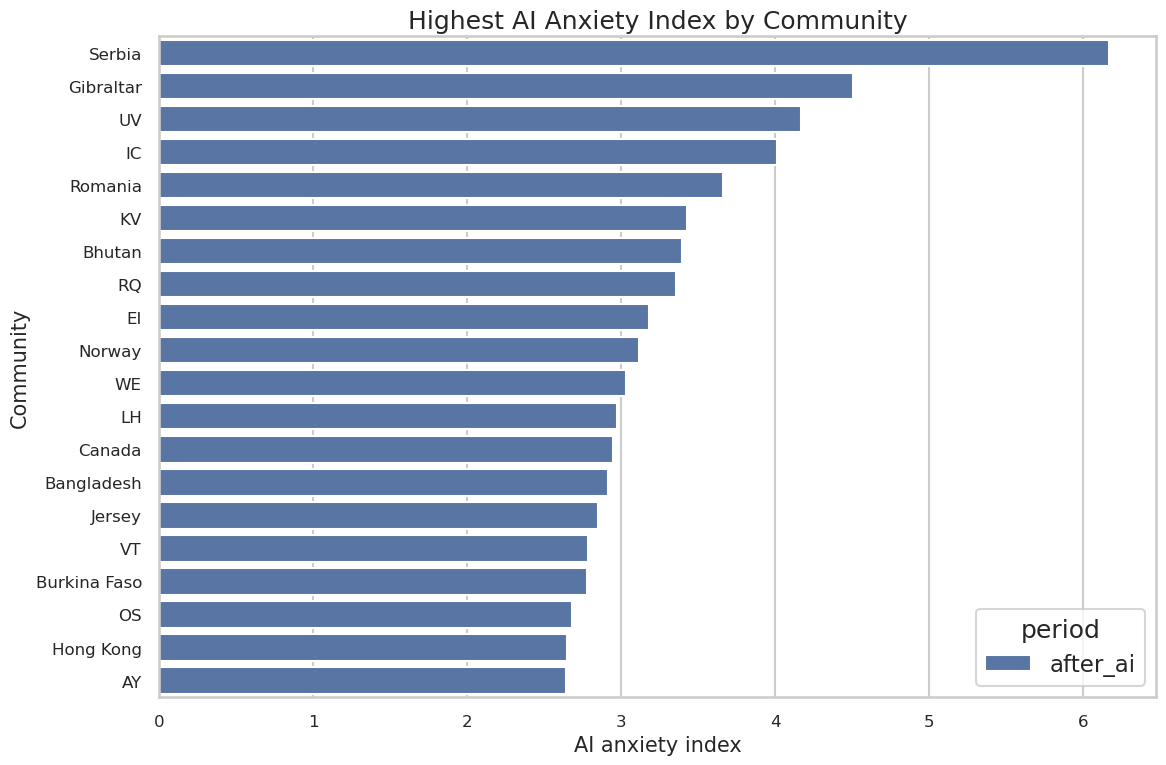

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/top_ai_anxiety_communities.png')

In [21]:
top_anxiety_regions = regional_sentiment.head(TOP_COMMUNITIES_TO_PLOT)
plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_anxiety_regions,
    y="community",
    x="ai_anxiety_index",
    hue="period",
)
plt.title("Highest AI Anxiety Index by Community")
plt.xlabel("AI anxiety index")
plt.ylabel("Community")
save_current_figure("top_ai_anxiety_communities.png")

In [22]:
def save_global_choropleth_map(
    regional_table: pd.DataFrame,
    filename: str = "ai_anxiety_global_choropleth.html",
) -> Path | None:
    """Save an interactive Plotly global choropleth map.

    Args:
        regional_table: Community-period sentiment summary.
        filename: HTML filename under the result folder.

    Returns:
        Path to the saved HTML map, or None when Plotly is unavailable.
    """

    if px is None:
        print(
            "Plotly is not installed. Install it with "
            "`conda install -n ai_map_env -c conda-forge plotly`."
        )
        return None

    map_table = regional_table.dropna(subset=["country_iso3"]).copy()
    if map_table.empty:
        print("No ISO country codes are available for the global map.")
        return None

    fig = px.choropleth(
        map_table,
        locations="country_iso3",
        color="ai_anxiety_index",
        hover_name="community",
        hover_data={
            "country_iso3": False,
            "period": True,
            "articles": ":,",
            "mean_tone": ":.3f",
            "anxiety_score": ":.3f",
            "opportunity_score": ":.3f",
            "ai_anxiety_index": ":.3f",
        },
        animation_frame="period",
        color_continuous_scale="RdBu_r",
        projection="natural earth",
        title="Global AI Anxiety Index by Country",
    )
    fig.update_layout(
        coloraxis_colorbar_title="AI anxiety index",
        margin={"l": 0, "r": 0, "t": 60, "b": 0},
    )

    path = result_dir / filename
    fig.write_html(path)
    print(f"Saved interactive global map: {path}")
    if running_in_notebook():
        fig.show()
    return path

In [23]:
save_global_choropleth_map(regional_sentiment)

Saved interactive global map: /home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_global_choropleth.html


PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_global_choropleth.html')

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_geographic_scatter.png


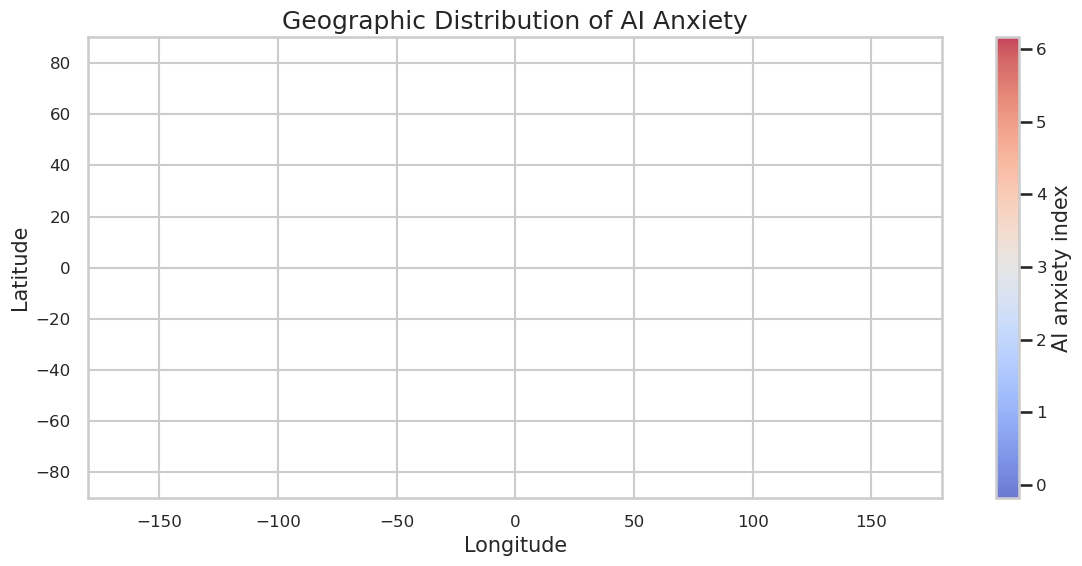

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/ai_anxiety_geographic_scatter.png')

In [24]:
plt.figure(figsize=(12, 6))
map_data = regional_sentiment.dropna(subset=["latitude", "longitude"])
scatter = plt.scatter(
    map_data["longitude"],
    map_data["latitude"],
    s=(map_data["articles"].clip(upper=10_000) / 60) + 20,
    c=map_data["ai_anxiety_index"],
    cmap="coolwarm",
    alpha=0.75,
)
plt.colorbar(scatter, label="AI anxiety index")
plt.title("Geographic Distribution of AI Anxiety")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
save_current_figure("ai_anxiety_geographic_scatter.png")

## Temporal Analysis: Before and After AI

### Calculation

In [25]:
monthly_sentiment = (
    articles.groupby(["period", "month"], as_index=False)
    .agg(
        articles=("gkg_record_id", "count"),
        mean_tone=("tone", "mean"),
        mean_ai_anxiety_index=("ai_anxiety_index", "mean"),
    )
    .sort_values(["period", "month"])
)
save_table(monthly_sentiment, "monthly_sentiment_summary.csv")
monthly_sentiment

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/monthly_sentiment_summary.csv


,period,month,articles,mean_tone,mean_ai_anxiety_index
0,after_ai,2023-01-01,870417,-0.811,2.454
1,after_ai,2023-02-01,71047,-0.703,2.630
2,before_ai,2023-01-01,719851,-0.732,2.338


### Visualization

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/monthly_ai_anxiety_index.png


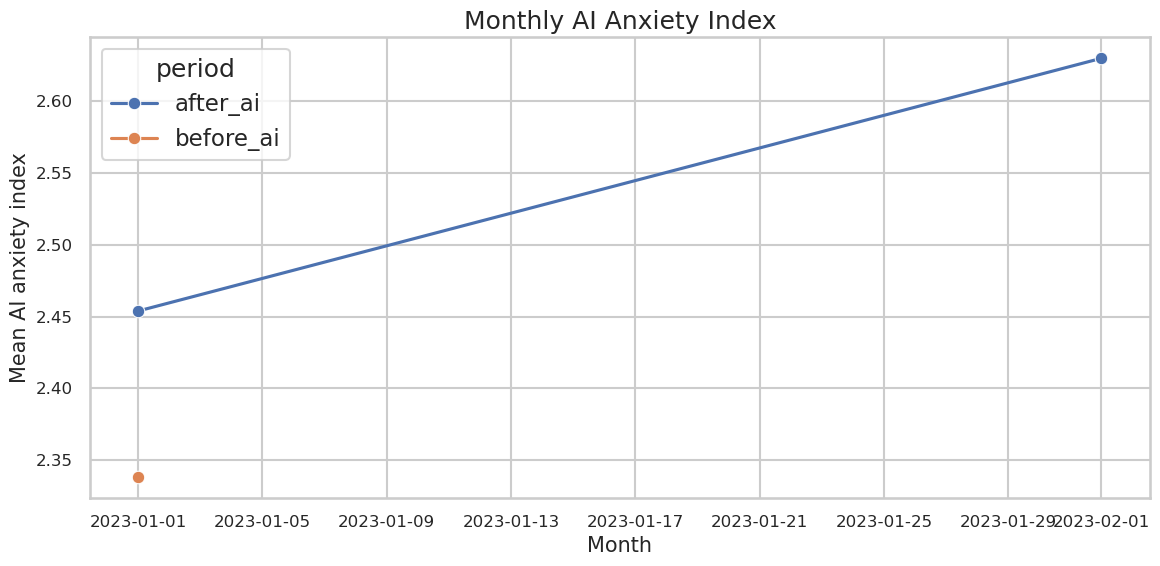

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/monthly_ai_anxiety_index.png')

In [26]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_sentiment,
    x="month",
    y="mean_ai_anxiety_index",
    hue="period",
    marker="o",
)
plt.title("Monthly AI Anxiety Index")
plt.xlabel("Month")
plt.ylabel("Mean AI anxiety index")
save_current_figure("monthly_ai_anxiety_index.png")

In [27]:
sentiment_distribution = (
    articles.groupby(["period", "sentiment"], as_index=False)
    .agg(articles=("gkg_record_id", "count"))
)
sentiment_distribution["share"] = sentiment_distribution.groupby("period")[
    "articles"
].transform(lambda values: values / values.sum())
save_table(sentiment_distribution, "sentiment_distribution.csv")
sentiment_distribution

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/sentiment_distribution.csv


,period,sentiment,articles,share
0,after_ai,negative,332623,0.353
1,after_ai,neutral,405571,0.431
2,after_ai,positive,203270,0.216
3,before_ai,negative,250014,0.347
4,before_ai,neutral,316378,0.440
5,before_ai,positive,153459,0.213


Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/sentiment_distribution_by_period.png


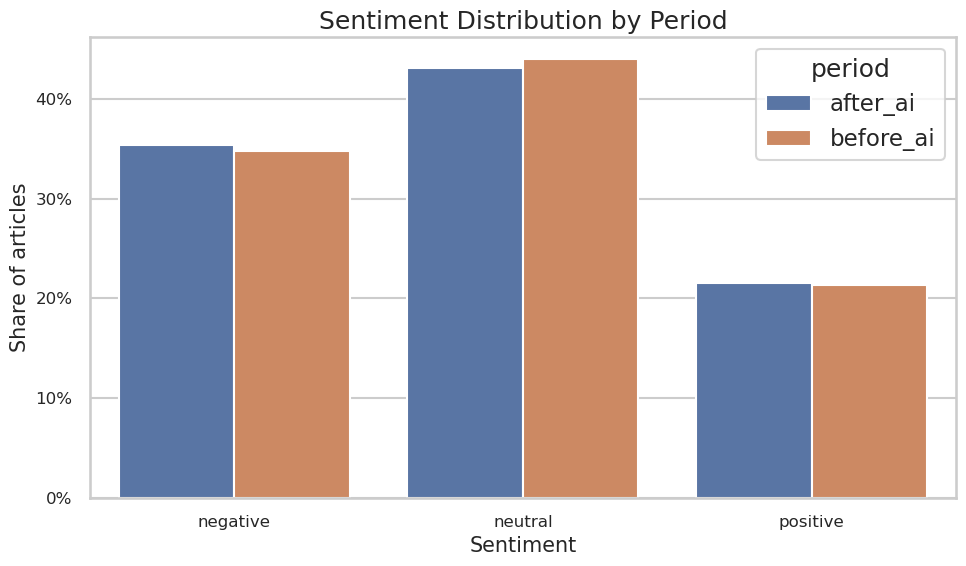

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/sentiment_distribution_by_period.png')

In [28]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=sentiment_distribution,
    x="sentiment",
    y="share",
    hue="period",
)
plt.title("Sentiment Distribution by Period")
plt.xlabel("Sentiment")
plt.ylabel("Share of articles")
plt.gca().yaxis.set_major_formatter(lambda value, _: f"{value:,.0%}")
save_current_figure("sentiment_distribution_by_period.png")

# Bipartite Network Construction
Build a bipartite graph connecting:

```mermaid
graph LR
    A["Community / Location"]
    B["Emotion / Sentiment"]

    A <--> B
```

Nodes represent:

- Type 1: Communities or locations.
- Type 2: Emotions and sentiment categories.

Edges represent:

- The strength of association between a community and an emotion.

## Graph Building

In [29]:
def build_bipartite_edges(data: pd.DataFrame) -> pd.DataFrame:
    """Build community-emotion weighted edges.

    Args:
        data: Article-level analysis records.

    Returns:
        Long table with community, emotion, and mean edge weight.
    """

    community_counts = data.groupby(["period", "community"]).size()
    valid_index = community_counts[
        community_counts >= MIN_ARTICLES_PER_COMMUNITY
    ].index
    valid_data = data.set_index(["period", "community"]).loc[valid_index]
    valid_data = valid_data.reset_index()

    edges = (
        valid_data.groupby(["period", "community"])[FEELING_COLUMNS]
        .mean()
        .reset_index()
        .melt(
            id_vars=["period", "community"],
            var_name="emotion",
            value_name="weight",
        )
        .dropna(subset=["weight"])
        .query("weight > 0")
        .sort_values(["period", "weight"], ascending=[True, False])
    )
    return edges

In [30]:
bipartite_edges = build_bipartite_edges(articles)
save_table(bipartite_edges, "community_emotion_bipartite_edges.csv")
bipartite_edges.head(20)

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/community_emotion_bipartite_edges.csv


,period,community,emotion,weight
161,after_ai,South Africa,liwc_anger,27.475
3137,after_ai,South Africa,wordnet_feeling,22.170
3119,after_ai,Réunion,wordnet_feeling,21.805
3132,after_ai,Serbia,wordnet_feeling,21.611
156,after_ai,Serbia,liwc_anger,18.005
187,after_ai,WE,liwc_anger,17.905
3033,after_ai,GK,wordnet_feeling,17.557
3140,after_ai,Switzerland,wordnet_feeling,16.835
3017,after_ai,Côte d'Ivoire,wordnet_feeling,14.900
20,after_ai,Bermuda,liwc_anger,14.798


In [31]:
def build_bipartite_graph(
    edge_table: pd.DataFrame,
    period: str,
    max_edges: int = 120,
) -> nx.Graph:
    """Build a NetworkX bipartite graph for one study period.

    Args:
        edge_table: Community-emotion edge table.
        period: Study period to graph.
        max_edges: Maximum strongest edges to keep in the display graph.

    Returns:
        Weighted NetworkX bipartite graph.
    """

    graph_edges = (
        edge_table.query("period == @period")
        .sort_values("weight", ascending=False)
        .head(max_edges)
    )
    graph = nx.Graph(period=period)
    for row in graph_edges.itertuples(index=False):
        graph.add_node(row.community, node_type="community", bipartite=0)
        graph.add_node(row.emotion, node_type="emotion", bipartite=1)
        graph.add_edge(
            row.community,
            row.emotion,
            weight=float(row.weight),
            period=row.period,
        )
    return graph

In [32]:
def draw_bipartite_graph(graph: nx.Graph, filename: str) -> None:
    """Draw and save a NetworkX bipartite graph.

    Args:
        graph: Bipartite community-emotion graph.
        filename: Figure filename under the result folder.
    """

    if graph.number_of_edges() == 0:
        print("No bipartite graph edges available to draw.")
        return

    communities = [
        node
        for node, data in graph.nodes(data=True)
        if data["node_type"] == "community"
    ]
    emotions = [
        node
        for node, data in graph.nodes(data=True)
        if data["node_type"] == "emotion"
    ]
    positions = {}
    positions.update(
        {
            node: (0, position)
            for position, node in enumerate(reversed(communities))
        }
    )
    positions.update(
        {node: (1, position) for position, node in enumerate(reversed(emotions))}
    )
    weights = [data["weight"] for _, _, data in graph.edges(data=True)]

    plt.figure(figsize=(14, 10))
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=communities,
        node_color="#4C78A8",
        node_size=650,
        alpha=0.9,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=emotions,
        node_color="#F58518",
        node_size=900,
        alpha=0.9,
    )
    nx.draw_networkx_edges(
        graph,
        positions,
        width=[max(weight * 4, 0.3) for weight in weights],
        alpha=0.35,
        edge_color="#555555",
    )
    nx.draw_networkx_labels(graph, positions, font_size=9)
    plt.title("NetworkX Bipartite Community-Emotion Graph")
    plt.axis("off")
    save_current_figure(filename)

In [33]:
available_period = str(bipartite_edges["period"].iloc[0])
bipartite_graph = build_bipartite_graph(bipartite_edges, available_period)
save_graph_tables(bipartite_graph, "networkx_bipartite_graph")
bipartite_graph_summary = pd.DataFrame(
    [
        {
            "period": available_period,
            "nodes": bipartite_graph.number_of_nodes(),
            "edges": bipartite_graph.number_of_edges(),
            "density": nx.density(bipartite_graph),
        }
    ]
)
save_table(bipartite_graph_summary, "networkx_bipartite_graph_summary.csv")
bipartite_graph_summary

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/networkx_bipartite_graph_nodes.csv
Saved table: /home/amitner/Data-Mining-Assignments/Project/result/networkx_bipartite_graph_edges.csv
Saved table: /home/amitner/Data-Mining-Assignments/Project/result/networkx_bipartite_graph_summary.csv


,period,nodes,edges,density
0,after_ai,104,120,0.022


## Statistics and Visualization

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/strongest_community_emotion_edges.png


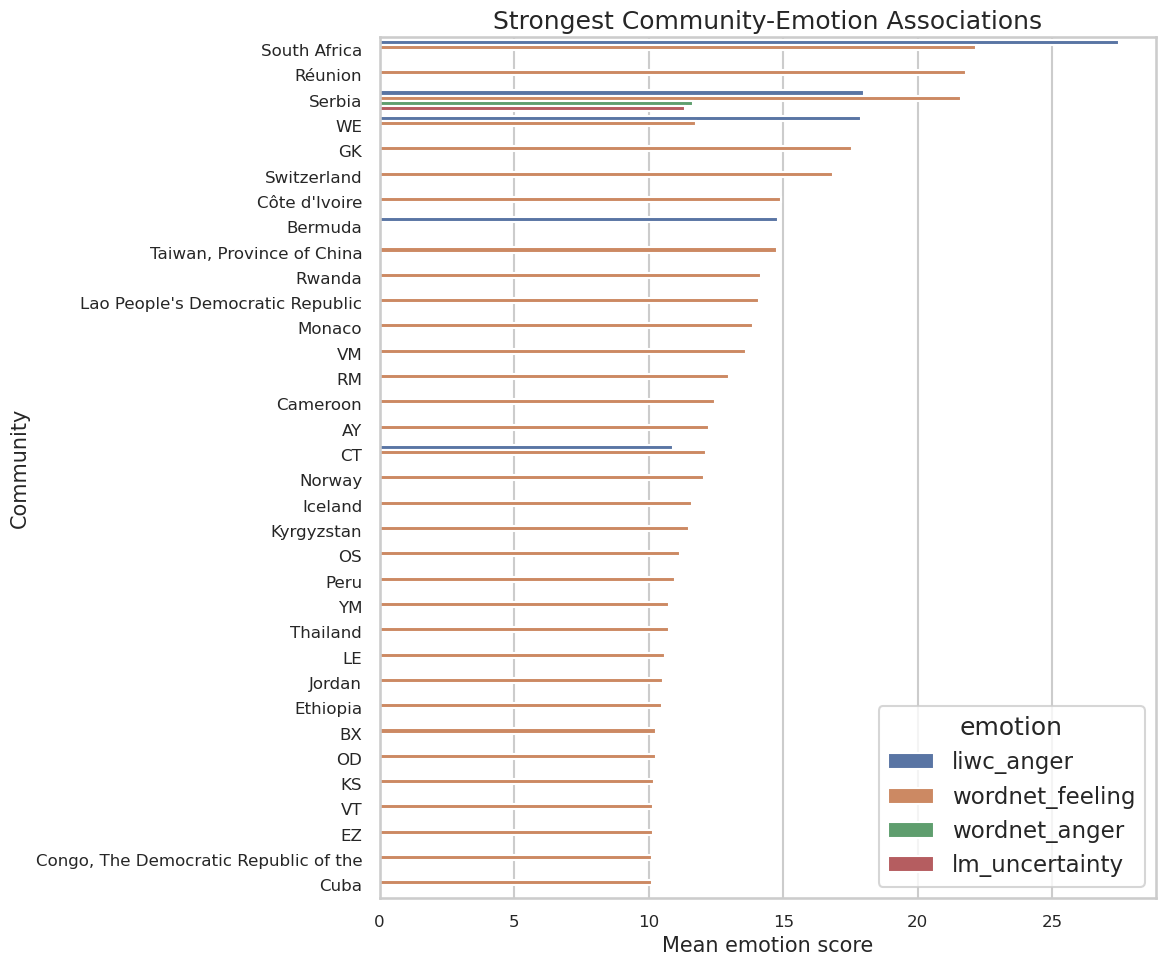

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/strongest_community_emotion_edges.png')

In [34]:
top_edges = bipartite_edges.head(40)
plt.figure(figsize=(12, 10))
sns.barplot(
    data=top_edges,
    y="community",
    x="weight",
    hue="emotion",
)
plt.title("Strongest Community-Emotion Associations")
plt.xlabel("Mean emotion score")
plt.ylabel("Community")
save_current_figure("strongest_community_emotion_edges.png")

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/networkx_bipartite_community_emotion_graph.png


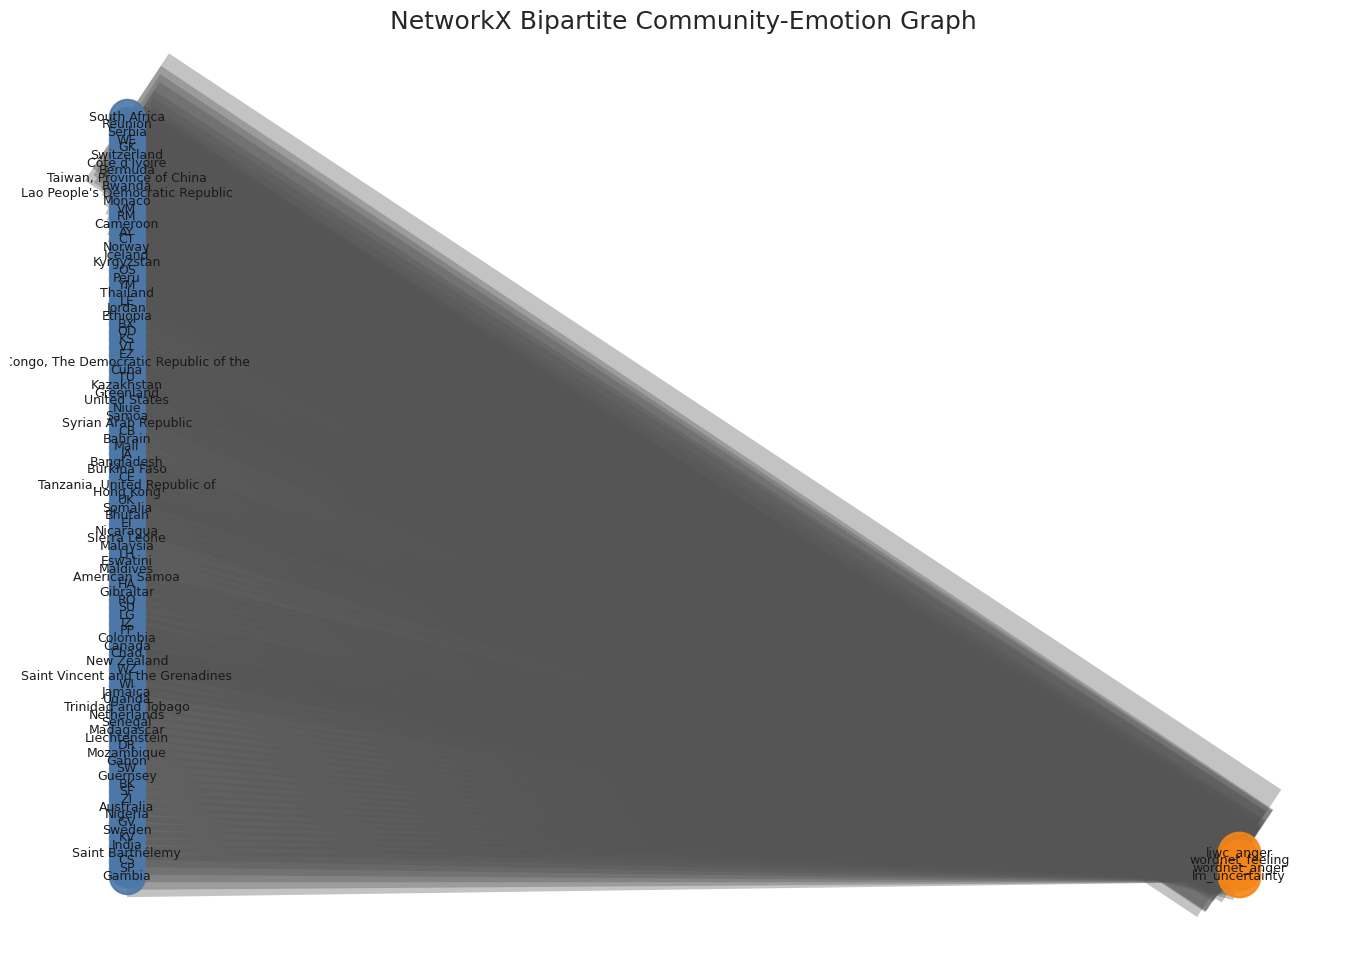

In [35]:
draw_bipartite_graph(
    bipartite_graph,
    "networkx_bipartite_community_emotion_graph.png",
)

# Community Similarity Network

Project the bipartite graph into a community similarity network:

```mermaid
graph LR
    A["Community A"]
    B["Community B"]

    A <--> B
```

Connections are weighted by:

- Shared emotional patterns.
- Similar sentiment distributions.
- Common labor-market concerns.

## Graph Building

In [36]:
def build_similarity_edges(edge_table: pd.DataFrame) -> pd.DataFrame:
    """Project community-emotion edges with NetworkX.

    Args:
        edge_table: Bipartite community-emotion edge table.

    Returns:
        Community-community weighted similarity edges.
    """

    similarity_rows = []
    for period, period_edges in edge_table.groupby("period"):
        period_graph = build_bipartite_graph(
            period_edges,
            str(period),
            max_edges=len(period_edges),
        )
        communities = [
            node
            for node, data in period_graph.nodes(data=True)
            if data["node_type"] == "community"
        ]
        similarity_graph = nx.bipartite.weighted_projected_graph(
            period_graph,
            communities,
        )
        for left_community, right_community, data in similarity_graph.edges(
            data=True
        ):
            left_degree = period_graph.degree(left_community)
            right_degree = period_graph.degree(right_community)
            denominator = max(left_degree + right_degree - data["weight"], 1)
            similarity = data["weight"] / denominator
            similarity_rows.append(
                {
                    "period": period,
                    "community_a": left_community,
                    "community_b": right_community,
                    "shared_emotions": data["weight"],
                    "similarity": similarity,
                }
            )
    return (
        pd.DataFrame(similarity_rows)
        .sort_values(["period", "similarity"], ascending=[True, False])
        .reset_index(drop=True)
    )

In [37]:
community_similarity = build_similarity_edges(bipartite_edges)
save_table(community_similarity, "community_similarity_edges.csv")
community_similarity.head(20)

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/community_similarity_edges.csv


,period,community_a,community_b,shared_emotions,similarity
0,after_ai,South Africa,Samoa,9,1.000
1,after_ai,South Africa,"Congo, The Democratic Republic of the",9,1.000
2,after_ai,South Africa,"Bolivia, Plurinational State of",9,1.000
3,after_ai,South Africa,"Iran, Islamic Republic of",9,1.000
4,after_ai,South Africa,Mali,9,1.000
5,after_ai,South Africa,VT,9,1.000
6,after_ai,South Africa,AY,9,1.000
7,after_ai,South Africa,Kazakhstan,9,1.000
8,after_ai,South Africa,Senegal,9,1.000
9,after_ai,South Africa,Jersey,9,1.000


In [38]:
def build_similarity_graph(
    similarity_table: pd.DataFrame,
    period: str,
    min_similarity: float = 0.35,
    max_edges: int = 120,
) -> nx.Graph:
    """Build a NetworkX community similarity graph.

    Args:
        similarity_table: Community-community similarity edge table.
        period: Study period to graph.
        min_similarity: Minimum similarity value to keep.
        max_edges: Maximum strongest edges to keep in the display graph.

    Returns:
        Weighted NetworkX community similarity graph.
    """

    graph_edges = (
        similarity_table.query(
            "period == @period and similarity >= @min_similarity"
        )
        .sort_values("similarity", ascending=False)
        .head(max_edges)
    )
    graph = nx.Graph(period=period)
    for row in graph_edges.itertuples(index=False):
        graph.add_node(row.community_a, node_type="community")
        graph.add_node(row.community_b, node_type="community")
        graph.add_edge(
            row.community_a,
            row.community_b,
            weight=float(row.similarity),
            shared_emotions=int(row.shared_emotions),
            period=row.period,
        )
    return graph

In [39]:
def draw_similarity_graph(graph: nx.Graph, filename: str) -> None:
    """Draw and save a NetworkX community similarity graph.

    Args:
        graph: Weighted community similarity graph.
        filename: Figure filename under the result folder.
    """

    if graph.number_of_edges() == 0:
        print("No community similarity graph edges available to draw.")
        return

    degrees = dict(graph.degree())
    positions = nx.spring_layout(graph, weight="weight", seed=42, k=0.8)
    weights = [data["weight"] for _, _, data in graph.edges(data=True)]
    node_sizes = [350 + degrees[node] * 80 for node in graph.nodes()]

    plt.figure(figsize=(14, 10))
    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=node_sizes,
        node_color="#54A24B",
        alpha=0.85,
    )
    nx.draw_networkx_edges(
        graph,
        positions,
        width=[max(weight * 4, 0.5) for weight in weights],
        edge_color="#666666",
        alpha=0.35,
    )
    nx.draw_networkx_labels(graph, positions, font_size=9)
    plt.title("NetworkX Community Similarity Graph")
    plt.axis("off")
    save_current_figure(filename)

In [40]:
similarity_graph = build_similarity_graph(community_similarity, available_period)
save_graph_tables(similarity_graph, "networkx_similarity_graph")
similarity_graph_summary = pd.DataFrame(
    [
        {
            "period": available_period,
            "nodes": similarity_graph.number_of_nodes(),
            "edges": similarity_graph.number_of_edges(),
            "density": nx.density(similarity_graph),
            "connected_components": nx.number_connected_components(
                similarity_graph
            )
            if similarity_graph.number_of_nodes() > 0
            else 0,
        }
    ]
)
save_table(similarity_graph_summary, "networkx_similarity_graph_summary.csv")
similarity_graph_summary

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/networkx_similarity_graph_nodes.csv
Saved table: /home/amitner/Data-Mining-Assignments/Project/result/networkx_similarity_graph_edges.csv
Saved table: /home/amitner/Data-Mining-Assignments/Project/result/networkx_similarity_graph_summary.csv


,period,nodes,edges,density,connected_components
0,after_ai,93,120,0.028,2


## Statistics and Visualization

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/top_community_similarity_edges.png


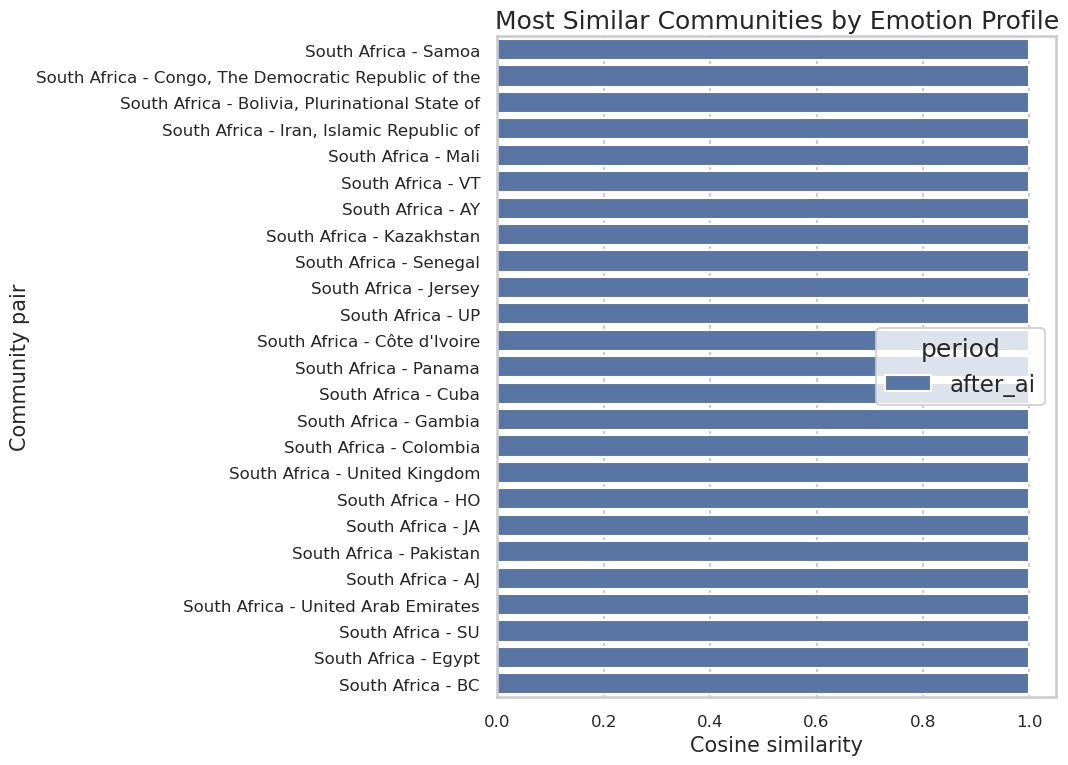

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/top_community_similarity_edges.png')

In [41]:
top_similarity = community_similarity.head(25)
plt.figure(figsize=(11, 8))
sns.barplot(
    data=top_similarity,
    y=top_similarity["community_a"] + " - " + top_similarity["community_b"],
    x="similarity",
    hue="period",
)
plt.title("Most Similar Communities by Emotion Profile")
plt.xlabel("Cosine similarity")
plt.ylabel("Community pair")
save_current_figure("top_community_similarity_edges.png")

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/networkx_community_similarity_graph.png


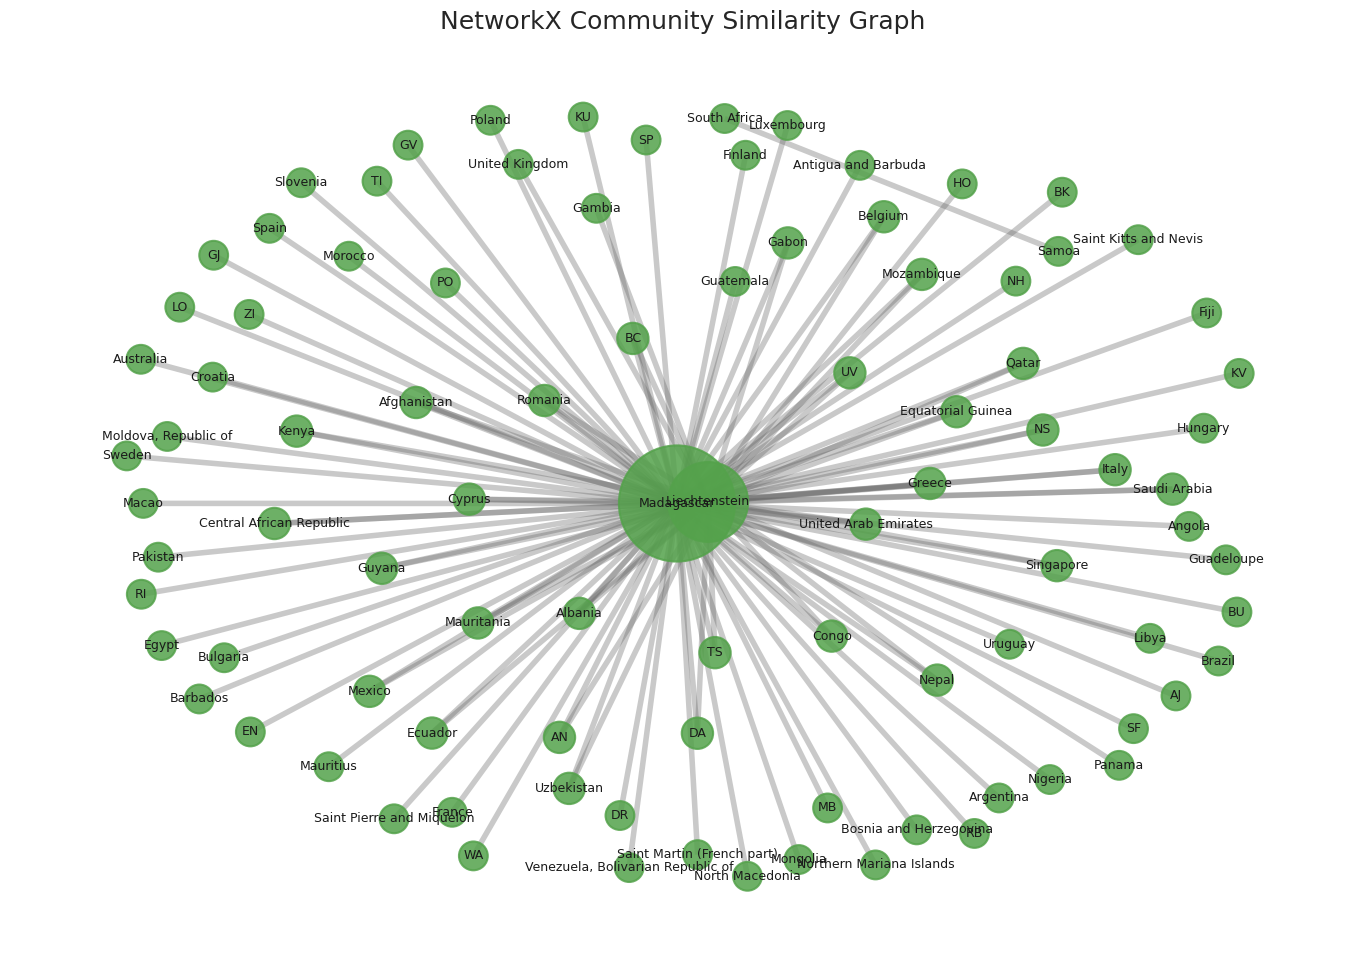

In [42]:
draw_similarity_graph(
    similarity_graph,
    "networkx_community_similarity_graph.png",
)

# Polarization Analysis
Analyze:

- How communities perceived the labor market before and after the rise of generative AI.
- Which communities shared similar labor-market perceptions before AI.
- Which communities became more different or polarized after AI.

## Calculation

In [43]:
def build_polarization_summary(
    regional_table: pd.DataFrame,
) -> pd.DataFrame:
    """Compare community anxiety before and after AI when both periods exist.

    Args:
        regional_table: Community-period regional sentiment table.

    Returns:
        Before-after comparison table. Empty when a period is unavailable.
    """

    required_periods = {"before_ai", "after_ai"}
    available_periods = set(regional_table["period"].dropna())
    if not required_periods.issubset(available_periods):
        missing = sorted(required_periods - available_periods)
        print(f"Skipping before/after polarization deltas. Missing: {missing}")
        return pd.DataFrame()

    pivot = regional_table.pivot_table(
        index="community",
        columns="period",
        values="ai_anxiety_index",
    ).dropna()
    pivot["anxiety_change"] = pivot["after_ai"] - pivot["before_ai"]
    pivot["polarization_direction"] = pivot["anxiety_change"].map(
        lambda value: "more anxious" if value > 0 else "less anxious"
    )
    return pivot.reset_index().sort_values(
        "anxiety_change",
        ascending=False,
    )

In [44]:
polarization_summary = build_polarization_summary(regional_sentiment)
if not polarization_summary.empty:
    save_table(polarization_summary, "polarization_before_after_summary.csv")
polarization_summary.head(20)

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/polarization_before_after_summary.csv


period,community,after_ai,before_ai,anxiety_change,polarization_direction
165,UV,4.165,0.649,3.516,more anxious
133,RQ,3.356,1.477,1.879,more anxious
147,Serbia,6.164,4.650,1.514,more anxious
18,Bermuda,1.994,0.692,1.302,more anxious
46,Egypt,1.533,0.314,1.220,more anxious
176,WE,3.029,1.888,1.142,more anxious
173,VT,2.783,1.780,1.003,more anxious
43,EN,2.133,1.144,0.989,more anxious
22,Bulgaria,2.371,1.408,0.963,more anxious
62,Guernsey,1.209,0.288,0.921,more anxious


## Statistics and Visualization

Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/polarization_before_after_changes.png


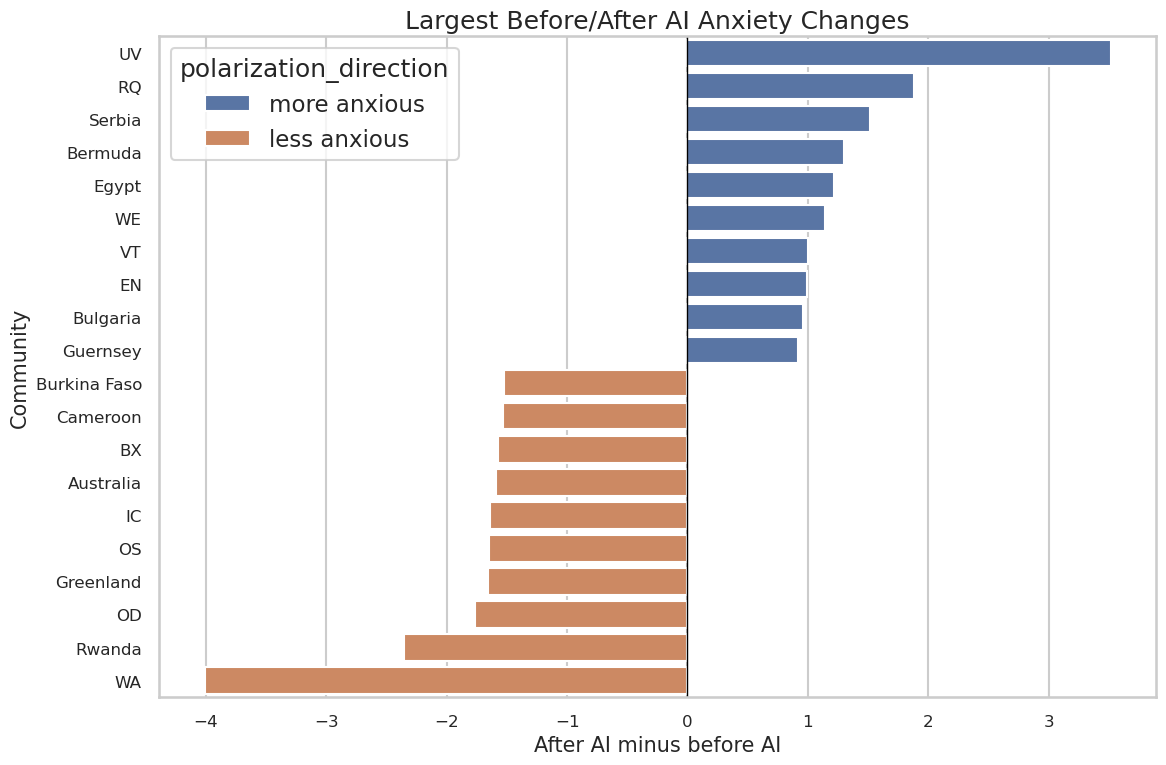

In [45]:
if not polarization_summary.empty:
    top_changes = pd.concat(
        [
            polarization_summary.head(10),
            polarization_summary.tail(10),
        ]
    )
    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=top_changes,
        y="community",
        x="anxiety_change",
        hue="polarization_direction",
    )
    plt.axvline(0, color="black", linewidth=1)
    plt.title("Largest Before/After AI Anxiety Changes")
    plt.xlabel("After AI minus before AI")
    plt.ylabel("Community")
    save_current_figure("polarization_before_after_changes.png")

# Before vs. After AI Comparison

## Calculation

In [46]:
comparison_summary = period_summary.copy()
if len(comparison_summary) > 1:
    comparison_summary["article_share"] = (
        comparison_summary["articles"] / comparison_summary["articles"].sum()
    )
else:
    comparison_summary["article_share"] = 1.0

save_table(comparison_summary, "before_after_available_period_comparison.csv")
comparison_summary

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/before_after_available_period_comparison.csv


,period,articles,communities,mean_tone,mean_anxiety,mean_opportunity,mean_ai_anxiety_index,article_share
0,after_ai,941464,238,-0.803,3.727,2.042,2.467,0.567
1,before_ai,719851,237,-0.732,3.660,2.035,2.338,0.433


## Statistics and Visualization

In [47]:
emotion_period_summary = (
    articles.groupby("period")[FEELING_COLUMNS]
    .mean()
    .reset_index()
    .melt(id_vars="period", var_name="emotion", value_name="mean_score")
)
save_table(emotion_period_summary, "emotion_period_summary.csv")
emotion_period_summary.head(20)

Saved table: /home/amitner/Data-Mining-Assignments/Project/result/emotion_period_summary.csv


,period,emotion,mean_score
0,after_ai,liwc_anger,6.468
1,before_ai,liwc_anger,5.582
2,after_ai,liwc_anxiety,3.242
3,before_ai,liwc_anxiety,3.242
4,after_ai,lm_uncertainty,5.686
5,before_ai,lm_uncertainty,5.467
6,after_ai,wordnet_anger,3.323
7,before_ai,wordnet_anger,2.769
8,after_ai,wordnet_anxiety,2.237
9,before_ai,wordnet_anxiety,2.103


Saved figure: /home/amitner/Data-Mining-Assignments/Project/result/emotion_scores_by_period.png


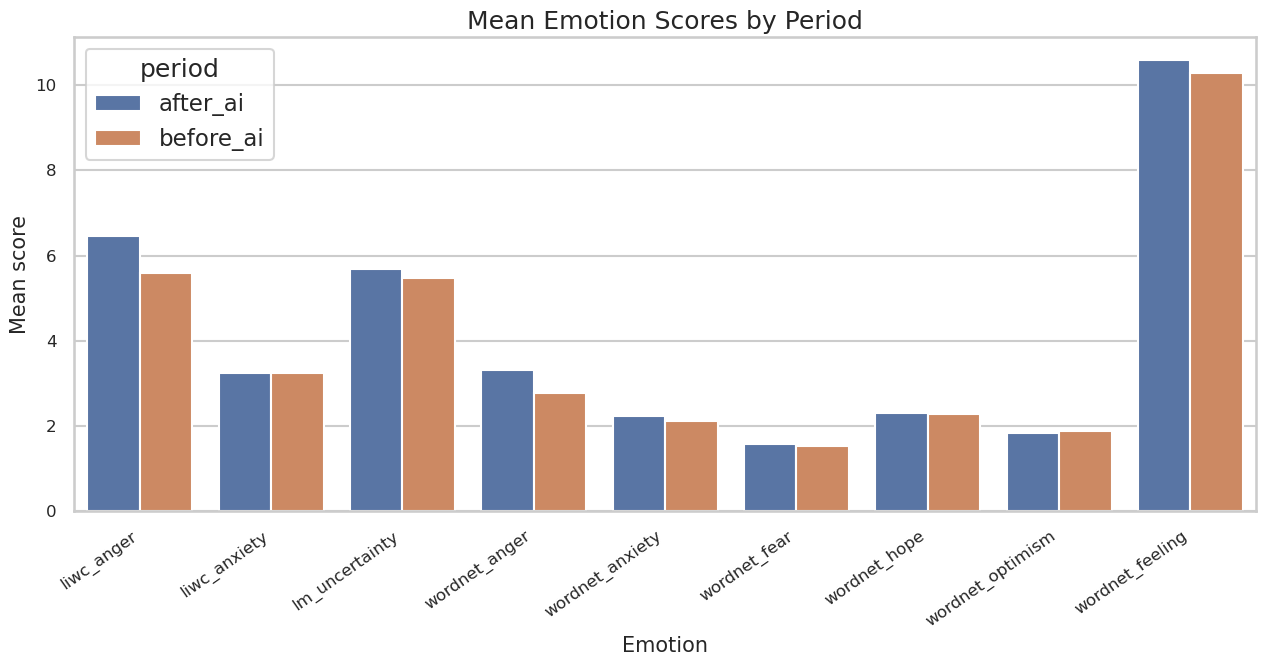

PosixPath('/home/amitner/Data-Mining-Assignments/Project/result/emotion_scores_by_period.png')

In [48]:
plt.figure(figsize=(13, 7))
sns.barplot(
    data=emotion_period_summary,
    x="emotion",
    y="mean_score",
    hue="period",
)
plt.title("Mean Emotion Scores by Period")
plt.xlabel("Emotion")
plt.ylabel("Mean score")
plt.xticks(rotation=35, ha="right")
save_current_figure("emotion_scores_by_period.png")

In [49]:
print("Analysis complete.")

Analysis complete.
